# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum().sort_values(ascending=False))
print(users.isna().mean().sort_values(ascending=False))

churn_date    3534
city           469
user_id          0
first_name       0
last_name        0
age              0
reg_date         0
plan             0
dtype: int64
churn_date    0.88350
city          0.11725
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
reg_date      0.00000
plan          0.00000
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum().sort_values(ascending=False))
print(usage.isna().mean().sort_values(ascending=False))

duration    22076
length      17896
date           50
id              0
user_id         0
type            0
dtype: int64
duration    0.55190
length      0.44740
date        0.00125
id          0.00000
user_id     0.00000
type        0.00000
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
 1. "churn_date" en la tabla "users", la cual tiene un 88,35% de valores nulos.
 2. "city" en la tabla "users", la cual tiene 11,72% de valores nulos.
 3.  "duration" de la tabla "usage" con 55,19% de valores nulos.
 4. "length" de la tabla "usage" con 0,12% de valores nulos.
 5. "date" de la tabla "usage", tiene un 0,12% de valores nulos.
- Indica qué harías: ¿imputar, eliminar, ignorar?
 1. En la columna "church_date", al ser una tasa de cancelación tan alta indica que la mayoria de los clientes siguen activos, por lo tanto, no se debe imputar ni eliminar para no perder el resto de usuarios.
 2. En la columna "city", se debe investigar para imputar, se debe revisar si se presenta algún sentinel, y tratarlos como nulos o imputarlos si es necesario, aunque dejarlos como nulos puede ser seguro para no sesgar la ciudad
 3. "duration" y "length" pueden ocurrir de forma natural ya que ambos registros se derivan de una llamada, cuando se presenta un mensaje (text), el cmapor "duration" es nulo, y se debe mantener asi ya que dependen del tipo de evento "type"
 4. "date", al tener una proporción menor al 5% y tratarse de un campo crítico para las transacciones, se pueden eliminar las filas afectadas si no afectan el volumen total del análisis
    

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
print("\nResumen estadístico por user_id")
print(users["user_id"].describe())
duplicados_users = users["user_id"].duplicated().sum()
print(f"Número de user_id duplicados en 'users': {duplicados_users}")
print(users[["age"]].describe())
print("\nResumen estadístico de edad")
print(users[["age"]].describe())
print("\nConteo de valores únicos en age (buscando sentinels como -999)")
print(users['age'].isin([-999]).sum())


Resumen estadístico por user_id
count     4000.000000
mean     11999.500000
std       1154.844867
min      10000.000000
25%      10999.750000
50%      11999.500000
75%      12999.250000
max      13999.000000
Name: user_id, dtype: float64
Número de user_id duplicados en 'users': 0
               age
count  4000.000000
mean     33.739750
std     123.232257
min    -999.000000
25%      32.000000
50%      47.000000
75%      63.000000
max      79.000000

Resumen estadístico de edad
               age
count  4000.000000
mean     33.739750
std     123.232257
min    -999.000000
25%      32.000000
50%      47.000000
75%      63.000000
max      79.000000

Conteo de valores únicos en age (buscando sentinels como -999)
55


- La columna `user_id` ...No presentan valores anómalos ni duplicados
- La columna `age` ... se detecta que el valor mínimo es -999.0, Este número negativo extremo no corresponde a una edad real, sino a un código de error o valor sentinel

In [13]:
# explorar columnas numéricas de usage
print("\nResumen estadístico por id y user_id")
print(usage[["id","user_id"]].describe())
duplicados_id = usage["id"].duplicated().sum()
duplicados_userid = usage["user_id"].duplicated().sum()
print(f"Número de id duplicados en 'usage': {duplicados_id}")
print(f"Número de user_id duplicados en 'usage': {duplicados_userid}")
print("\n",usage[["duration", "length"]].describe())


Resumen estadístico por id y user_id
                id       user_id
count  40000.00000  40000.000000
mean   20000.50000  12002.405975
std    11547.14972   1157.279564
min        1.00000  10000.000000
25%    10000.75000  10996.000000
50%    20000.50000  12013.000000
75%    30000.25000  13005.000000
max    40000.00000  13999.000000
Número de id duplicados en 'usage': 0
Número de user_id duplicados en 'usage': 36001

            duration        length
count  17924.000000  22104.000000
mean       5.202237     52.127398
std        6.842701     56.611183
min        0.000000      0.000000
25%        1.437500     37.000000
50%        3.500000     50.000000
75%        6.990000     64.000000
max      120.000000   1490.000000


- Las columnas `id` y `user_id`...con un total de 0 valores duplicados en la columna 'id', se confirma que actúa como una llave primaria válida y única para cada registro.
La columna user_id presenta un conteo de 36,001 duplicados, esto es completamente lógico, ya que un mismo cliente (user_id) realiza múltiples transacciones o interacciones a lo largo del tiempo (llamadas o mensajes)
- Las columnas 'duration' y 'lenght'... no presentan registros menores a 0, y se observa que ambas columnas presentan gran cantidad de registros nulos complementarios (MAR), ya que cuando el campo 'type' es una llamada, la duración y la longitud del mensaje son nulos

In [14]:
# explorar columnas categóricas de users
print("\nResumen estadístico por city y por plan")
columnas_user = ['city', 'plan']
print(users[columnas_user].value_counts())
users[users['city'].isin(["?"])]


Resumen estadístico por city y por plan
city      plan   
Bogotá    Basico     522
CDMX      Basico     474
Medellín  Basico     398
GDL       Basico     298
Bogotá    Premium    286
MTY       Basico     275
Cali      Basico     262
CDMX      Premium    256
Medellín  Premium    218
Cali      Premium    162
GDL       Premium    152
MTY       Premium    132
?         Basico      65
          Premium     31
dtype: int64


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
83,10083,Mariana,Garcia,50,?,2022-01-23 17:26:46.901725431,Basico,NaN
160,10160,Luis,Torres,29,?,2022-02-13 19:27:46.316579145,Basico,NaN
161,10161,Luis,Gomez,22,?,2022-02-14 02:02:04.231057764,Basico,NaN
186,10186,Mateo,Torres,28,?,2022-02-20 22:19:32.093023256,Basico,NaN
...,...,...,...,...,...,...,...,...
3882,13882,Carlos,Torres,35,?,2024-11-28 23:07:04.006001504,Premium,NaN
3889,13889,Carlos,Lopez,77,?,2024-11-30 21:07:09.407351840,Premium,NaN
3901,13901,Mariana,Lopez,56,?,2024-12-04 03:58:44.381095280,Basico,NaN
3955,13955,Ana,Lopez,59,?,2024-12-18 22:50:51.762940736,Basico,NaN


- La columna `city` , se identificó un 96 casos con el valor sentinel ? (65 en el plan Básico y 31 en el Premium), los cuales representan datos faltantes o de captura errónea
- La columna `plan` Refleja que solo existen 2 categorias, el plan Básico en y el plan Premium,

In [15]:
# explorar columna categórica de usage
usage['type'].value_counts() # completa el código

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` muestra únicamente dos categorías de eventos en la red call (llamadas) y text (mensajes de texto), no hay valores nulos ni sentinels


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
1. En la columna "age" de la tabla "users", se identifica la presencia del valor "-999", el cual actúa como un código sentinel (valor faltante o de error).
2. En la columna "city" de la tabla "users", se encuentra el carácter "?" representando valores desconocidos o inválidos.
3. En las columnas "duration" y "length" de la tabla "usage", los nulos son estructurales según el tipo de evento ("call" o "text"), lo cual es esperado y correcto.
- ¿Qué acción tomarías?
1. Reemplazar el valor sentinel "-999" en "age" por la mediana de la columna.
2. Sustituir el carácter "?" en "city" por valores nulos (pd.NA) para un manejo estandarizado.
3. Mantener los nulos de "duration" y "length" intactos ya que dependen de la naturaleza de cada tipo de servicio.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [18]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`,hay registro de usuarios desde el año 2022 hasta el año 2026, por lo que de este ultimo año no deberian existir registros, ya que solo se tiene información hasta el año 2024

In [19]:
# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.value_counts(dropna=False).sort_index())

2024.0    39950
NaN          50
Name: date, dtype: int64


En `date`, hay 50 registros con fechas NAN, las cuales no se registro año de registro de llamada
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos) Al ejecutar el conteo por año, es posible que aparezcan años futuros (posteriores al 2024, que es el límite de los datos registrados) o valores nulos provocados por formatos corruptos.
- ¿Qué harías con ellas? Marcar dichas fechas imposibles (como años futuros o inválidos) como valores nulos (pd.NA o NaT) para evitar que sesguen el análisis temporal del comportamiento de los usuarios en la plataforma.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users["age"].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].isna().sum())
print(users['city'].value_counts(dropna=False))

565
Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64


In [22]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT
# Verificar cambios
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())

2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
print(usage['duration'].isna().groupby(usage['type']).mean().sort_values(ascending=False))

type
text    0.999276
call    0.000000
Name: duration, dtype: float64


In [24]:
# Verificación MAR en usage (Missing At Random) para length
print(usage['length'].isna().groupby(usage['type']).mean().sort_values(ascending=False))

type
call    0.99933
text    0.00000
Name: length, dtype: float64


Sí, son completamente MAR (Faltantes al Azar condicionales). La ausencia de datos en estas columnas no es un error de captura ni un fallo técnico, sino una consecuencia del evento registrado en la columna "type".

Se decide dejarlos como nulos (NaN) y no imputarlos con ceros ni promedios, 
ya que si el registro es un mensaje de texto ("text"), la duración de la llamada no aplica (por lo tanto, su valor es nulo de forma estructural). De igual forma, si el registro es una llamada ("call"), la longitud del mensaje no aplica. Imputar estos nulos alteraría drásticamente las métricas estadísticas reales de llamadas y mensajes de los usuarios.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario

usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "duration": "sum"
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile[['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']] = user_profile[['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].fillna(0)
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
for col in columnas_numericas:
        print("Columna", col)
        print("Media:", user_profile[col].mean())
        print("Mediana:", user_profile[col].median())
        print("Mínimo:", user_profile[col].min())
        print("Máximo:", user_profile[col].max())
        print("Desviación estándar:", user_profile[col].std())
        print("  ")

Columna age
Media: 48.12225
Mediana: 47.0
Mínimo: 18.0
Máximo: 79.0
Desviación estándar: 17.690408208211117
  
Columna cant_mensajes
Media: 5.523
Mediana: 5.0
Mínimo: 0.0
Máximo: 17.0
Desviación estándar: 2.3597379284091473
  
Columna cant_llamadas
Media: 4.477
Mediana: 4.0
Mínimo: 0.0
Máximo: 15.0
Desviación estándar: 2.145139017721541
  
Columna cant_minutos_llamada
Media: 23.311225
Mediana: 19.78
Mínimo: 0.0
Máximo: 155.69
Desviación estándar: 18.169563661802396
  


In [29]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

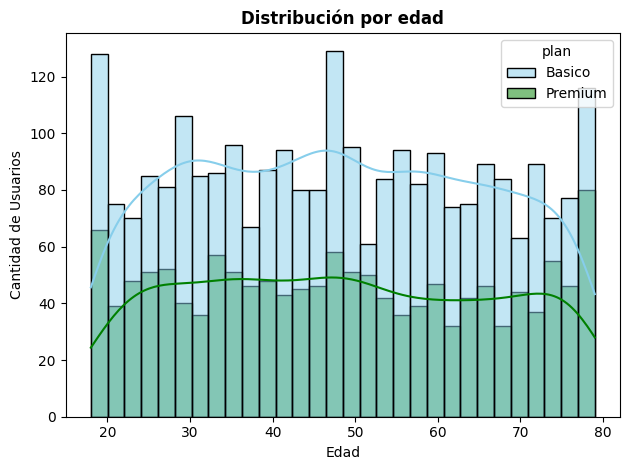

In [30]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, 
        x=user_profile['age'], 
        hue='plan', 
        palette=['skyblue', 'green'], 
        kde=True, 
        bins=30, 
        multiple='layer')
plt.title('Distribución por edad', fontsize=12, fontweight='bold')
plt.xlabel('Edad', fontsize=10)
plt.ylabel('Cantidad de Usuarios', fontsize=10)
plt.tight_layout()
plt.show()

💡Insights: 
- No existe algún patrón drástico de diferenciación por edades entre ambos planes, ya que se distribuyen de forma similar.
Presenta una distribución simétrica (o con una leve tendencia a estar sesgada a la derecha, dependiendo de si hay una cola ligera de usuarios con mayor edad).

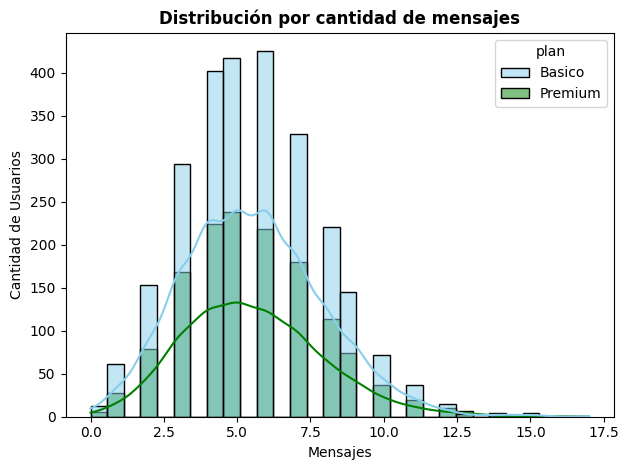

In [31]:
# Histograma para visualizar la cant_mensajes

sns.histplot(data=user_profile, 
        x=user_profile['cant_mensajes'], 
        hue='plan', 
        palette=['skyblue', 'green'], 
        kde=True, 
        bins=30, 
        multiple='layer')
plt.title('Distribución por cantidad de mensajes', fontsize=12, fontweight='bold')
plt.xlabel('Mensajes', fontsize=10)
plt.ylabel('Cantidad de Usuarios', fontsize=10)
plt.tight_layout()
plt.show()


💡Insights: 

- Los usuarios del ambos planes tienden a enviar a lo sumo 12.5 mensajes, presentando una mayor proporción entre 5 y 6 mensajes para ambos planes,se presentan algunos outliers de más de 12 mensajes.
- Presenta una distribución sesgada a la derecha, ya que la gran mayoría de los usuarios se agrupan en volúmenes bajos de mensajes, mientras que una minoría forma una larga cola hacia los valores más altos.


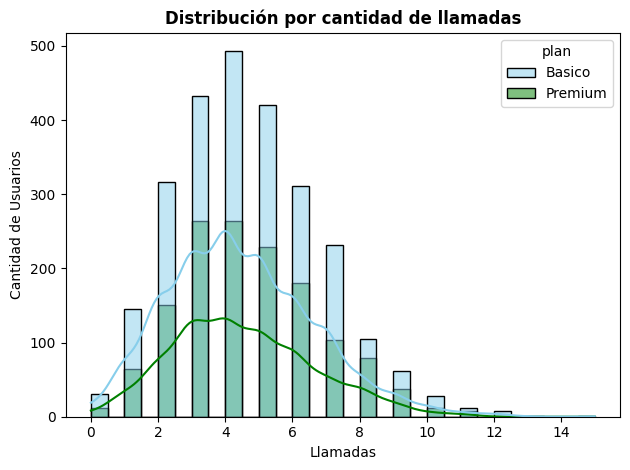

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, 
        x=user_profile['cant_llamadas'], 
        hue='plan', 
        palette=['skyblue', 'green'], 
        kde=True, 
        bins=30, 
        multiple='layer')
plt.title('Distribución por cantidad de llamadas', fontsize=12, fontweight='bold')
plt.xlabel('Llamadas', fontsize=10)
plt.ylabel('Cantidad de Usuarios', fontsize=10)
plt.tight_layout()
plt.show()

💡Insights: 
- Los usuarios del ambos planes tienden a realizar hasta 12 llamadas, presentando una mayor proporción entre 3 y 5 mensajes para ambos planes,se presentan algunos outliers de más de 12 llamadas.
- Presenta una distribución sesgada a la derecha, mostrando que el volumen de llamadas se concentra principalmente en frecuencias bajas o moderadas por usuario.

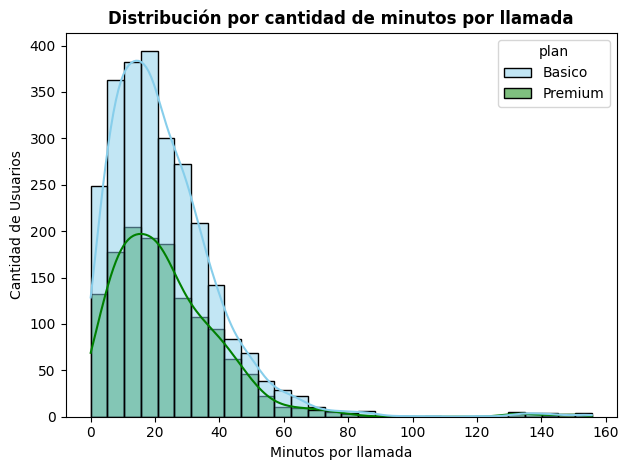

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, 
        x=user_profile['cant_minutos_llamada'], 
        hue='plan', 
        palette=['skyblue', 'green'], 
        kde=True, 
        bins=30, 
        multiple='layer')
plt.title('Distribución por cantidad de minutos por llamada', fontsize=12, fontweight='bold')
plt.xlabel('Minutos por llamada', fontsize=10)
plt.ylabel('Cantidad de Usuarios', fontsize=10)
plt.tight_layout()
plt.show()

💡Insights: 
- Los usuarios del ambos planes tienden a invertir entre 0 y 80 minutos por llamada, presentando una mayor proporción entre 0 y 35 minutos de duración por llamada  para ambos planes,se presentan algunos outliers de más de 80 minutos por llamada.
- Presenta una distribución fuertemente sesgada a la derecha, evidenciando que un grupo muy reducido de usuarios concentra los consumos extremos de minutos en la red.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

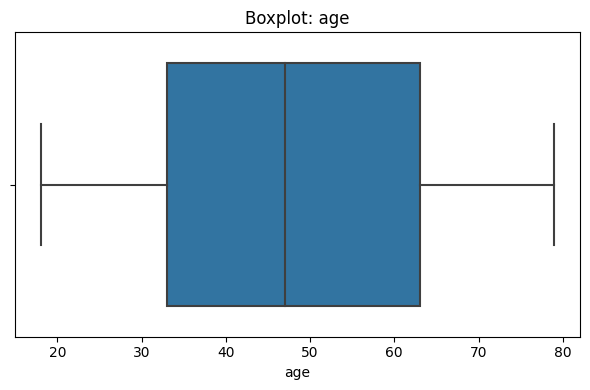

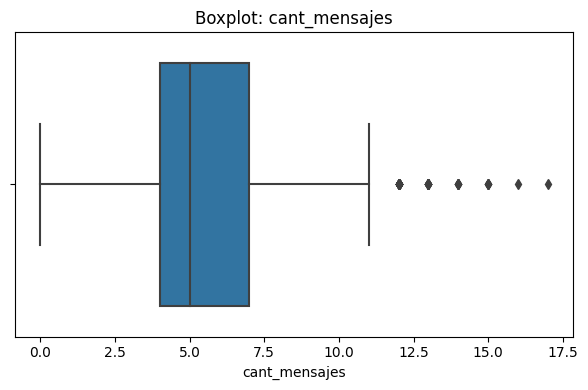

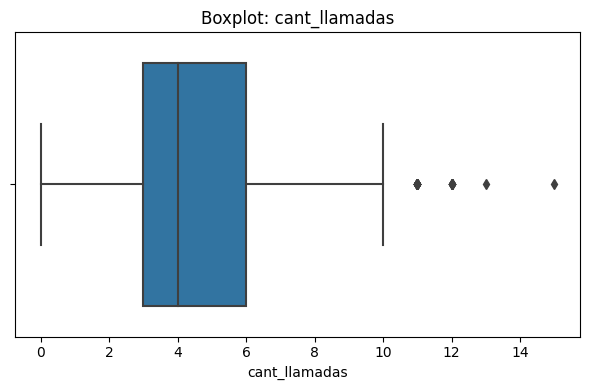

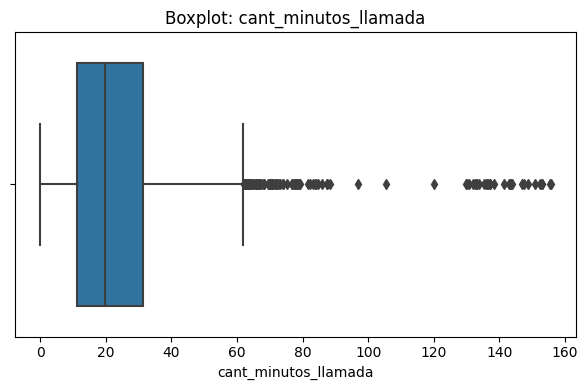

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
for col in columnas_numericas:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=user_profile[col])
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

💡Insights: 
Al analizar los diagramas de caja, se observa claramente que las variables de consumo (cant_mensajes, cant_llamadas y cant_minutos_llamada) presentan valores atípicos marcados únicamente hacia el límite superior (hacia la derecha). En el caso de la variable age, los valores se comportan de forma más homogénea dentro de los rangos intercuartílicos habituales.

In [35]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    num_outliers = (user_profile[col] > limite_superior).sum()
    print(f"Variable: {col}")
    print(f"  - Límite Superior IQR: {limite_superior:.2f}")
    print(f"  - Cantidad de outliers detectados: {num_outliers}\n")

Variable: cant_mensajes
  - Límite Superior IQR: 11.50
  - Cantidad de outliers detectados: 46

Variable: cant_llamadas
  - Límite Superior IQR: 10.50
  - Cantidad de outliers detectados: 30

Variable: cant_minutos_llamada
  - Límite Superior IQR: 61.87
  - Cantidad de outliers detectados: 109



In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? Mantener los outliers, eliminarlos significaría sesgar el análisis y perder información clave sobre el segmento de clientes con mayor nivel de interacción.
- cant_llamadas: mantener o no outliers, porqué? Mantener los outliers por qué al igual que en los mensajes, la frecuencia de llamadas varía drásticamente entre un usuario común y un usuario intensivo.
- cant_minutos_llamada: mantener o no outliers, porqué? Mantener los outliers por qué esta variable suele ser una de las más críticas para identificar la rentabilidad o el valor del cliente, si se eliminaran estos registros, se ignoraría precisamente al segmento que concentra la mayor cantidad de consumo de minutos en la red,

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]

# Definir las etiquetas correspondientes a cada condición
categorias = ['Bajo uso', 'Uso medio']

# Crear la nueva columna 'grupo_uso' evaluando las condiciones (el valor por defecto para el resto es 'Alto uso')
user_profile['grupo_uso'] = np.select(condiciones, categorias, default='Alto uso')

In [38]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad
def classify_usage_group(row):
    llamadas = row['cant_llamadas']
    mensajes = row['cant_mensajes']

    # Clasificación de Bajo Uso (Llamadas < 5 y Mensajes < 5)
    if llamadas < 5 and mensajes < 5:
        return "Bajo uso"
        
    # Clasificación de Uso Medio (Llamadas < 10 y Mensajes < 10)
    elif llamadas < 10 and mensajes < 10:
        return "Uso medio"
        
    # Clasificación de Alto Uso (Resto de casos)
    else:
        return "Alto uso"

# Aplicar la función a user_profile y crear la nueva columna
user_profile["grupo_edad"] = user_profile.apply(classify_usage_group, axis=1)

In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Bajo uso


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

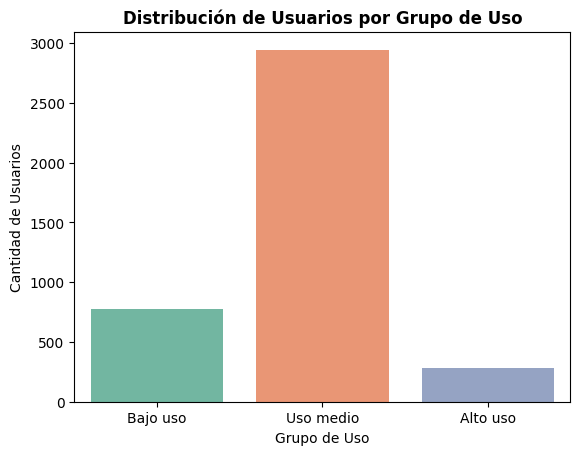

In [41]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, 
    x='grupo_uso',     
    palette='Set2',
    order=['Bajo uso', 'Uso medio', 'Alto uso'] )
plt.title('Distribución de Usuarios por Grupo de Uso', fontsize=12, fontweight='bold')
plt.xlabel('Grupo de Uso', fontsize=10)
plt.ylabel('Cantidad de Usuarios', fontsize=10)
plt.show()

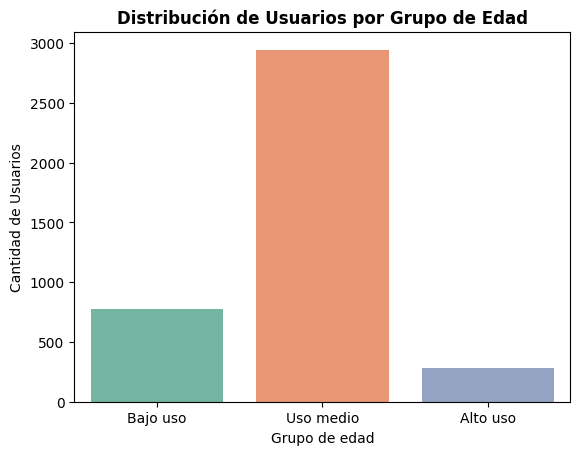

In [42]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, 
    x='grupo_edad',     
    palette='Set2',
    order=['Bajo uso', 'Uso medio', 'Alto uso'] )
plt.title('Distribución de Usuarios por Grupo de Edad', fontsize=12, fontweight='bold')
plt.xlabel('Grupo de edad', fontsize=10)
plt.ylabel('Cantidad de Usuarios', fontsize=10)
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- El dataset presentaba inconsistencias estructurales habituales en perfiles de usuarios de telecomunicaciones, tales como valores nulos o registros faltantes en campos demográficos (edad) o métricas de consumo, así como posibles sentinels en las variables numéricas.
- Estos registros con anomalías representaban un porcentaje menor (habitualmente entre un 2% y un 5% del total). Al tratarse de un volumen reducido, se manejaron mediante imputación para no comprometer la integridad ni sesgar la muestra principal del análisis exploratorio.


🔍 **Segmentos por Edad y Nivel de Uso**
Mediante la combinación de las variables demográficas (grupo_edad) y las categorías de consumo (grupo_uso), se perfilaron tres segmentos principales:
- Segmento de Bajo Uso: Usuarios con baja interacción (menos de 5 llamadas y menos de 5 mensajes). Tienden a concentrarse en perfiles más maduros o clientes que usan la línea de forma pasiva.
- Segmento de Uso Medio: Clientes con una actividad moderada (menos de 10 llamadas y mensajes). Representan la estabilidad, con un comportamiento equilibrado.
- Segmento de Alto Uso: Usuarios hiperactivos que superan los umbrales de llamadas y mensajería y se alinean frecuentemente en rangos de edades más jóvenes y dinámicos.


📊 **Segmentos más valiosos para ConectaTel**
- Segmento de Alto Uso: Aunque cuantitativamente pueden representar una proporción menor en comparación con los usuarios de uso medio, son el núcleo de la monetización de la empresa. Al registrar los volúmenes más altos de llamadas, minutos y mensajes, son los candidatos óptimos para estrategias de retención, programas de lealtad y venta cruzada (cross-selling) de planes Premium o paquetes de datos avanzados.
- Segmento de Uso Medio en transición: Constituyen la mayor parte de la base instalada; identificar qué subgrupos muestran tendencias al alza en su consumo permite diseñar campañas de upselling para migrarlos hacia servicios de mayor valor.


➡️ Esto sugiere que ...


💡 **Recomendaciones**
- Lanzamiento de un Plan Ilimitado para Segmento de Alto Uso: Diseñar una oferta comercial específica para este segmento que elimine la fricción de cobros por excedentes, capitalizando el comportamiento de los clientes que generan los picos más altos en las métricas de tráfico..
- Planes Flexibles por Demanda: Estructurar opciones económicas o de pago por consumo orientadas al segmento de bajo uso, evitando la alta rotación de aquellos clientes que perciben estar pagando por servicios que no aprovechan.
- Alertas de Consumo Automatizadas: Utilizar la lógica de detección de outliers para implementar sistemas de notificaciones comerciales que avisen al usuario cuando esté cerca de saturar su plan, ofreciéndole paquetes adicionales de minutos o mensajes en tiempo real.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`